# Library: GPU / cuML

In [1]:
# ============================================================
# 1. STANDARD LIBRARY
# ============================================================

from time import perf_counter


# ============================================================
# 2. DATA MANIPULATION AND VISUALIZATION (CPU)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency


# ============================================================
# 3. CPU PREPROCESSING, SPLITS, AND EVALUATION
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid


# ============================================================
# 4. GPU ARRAYS AND cuML MODELS
# ============================================================

try:
    import cupy as cp
    from cuml.linear_model import LogisticRegression as cuLogisticRegression
    from cuml.svm import LinearSVC as cuLinearSVC
    from cuml.ensemble import RandomForestClassifier as cuRandomForestClassifier
except ImportError as exc:
    raise ImportError(
        "Notebook ini memerlukan environment RAPIDS dengan CuPy dan cuML. "
        "Pilih kernel yang terhubung ke GPU CUDA sebelum menjalankan notebook."
    ) from exc

try:
    device_id = cp.cuda.runtime.getDevice()
    device_name = cp.cuda.runtime.getDeviceProperties(device_id)["name"].decode()
except cp.cuda.runtime.CUDARuntimeError as exc:
    raise RuntimeError(
        "CUDA GPU tidak tersedia. Jalankan notebook pada mesin dengan driver "
        "NVIDIA dan environment RAPIDS yang kompatibel."
    ) from exc


# ============================================================
# 5. EXPERIMENT CONFIGURATION AND TIMING HELPERS
# ============================================================

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")


def dense_float32(matrix):
    """Materialize sparse CPU output and return a contiguous float32 array."""
    if hasattr(matrix, "toarray"):
        matrix = matrix.toarray()
    return np.ascontiguousarray(np.asarray(matrix, dtype=np.float32))


def upload_to_gpu(features_cpu, labels_cpu):
    """Measure one host-to-device upload and keep the arrays on the GPU."""
    cp.cuda.Stream.null.synchronize()
    start = perf_counter()
    features_gpu = cp.asarray(features_cpu)
    labels_gpu = cp.asarray(labels_cpu)
    cp.cuda.Stream.null.synchronize()
    return features_gpu, labels_gpu, perf_counter() - start


def timed_gpu_call(function):
    """Measure an asynchronous GPU operation accurately."""
    cp.cuda.Stream.null.synchronize()
    start = perf_counter()
    result = function()
    cp.cuda.Stream.null.synchronize()
    return result, perf_counter() - start


def copy_prediction_to_cpu(prediction_gpu):
    cp.cuda.Stream.null.synchronize()
    start = perf_counter()
    prediction_cpu = cp.asnumpy(prediction_gpu).ravel().astype(np.int32)
    cp.cuda.Stream.null.synchronize()
    return prediction_cpu, perf_counter() - start


def fit_predict_gpu(models, x_train_gpu, y_train_gpu, x_test_gpu):
    """Fit models sequentially on one GPU and record fit, predict, and D2H time."""
    trained_models = {}
    predictions = {}
    timing_rows = []

    for name, model in models.items():
        _, fit_seconds = timed_gpu_call(
            lambda model=model: model.fit(x_train_gpu, y_train_gpu)
        )
        prediction_gpu, predict_seconds = timed_gpu_call(
            lambda model=model: model.predict(x_test_gpu)
        )
        prediction_cpu, download_seconds = copy_prediction_to_cpu(prediction_gpu)

        trained_models[name] = model
        predictions[name] = prediction_cpu
        timing_rows.append(
            {
                "Model": name,
                "Fit GPU (s)": fit_seconds,
                "Predict GPU (s)": predict_seconds,
                "GPU → CPU (s)": download_seconds,
                "Total model (s)": fit_seconds + predict_seconds + download_seconds,
            }
        )
        print(f"{name} selesai dilatih dalam {fit_seconds:.3f} detik.")

    return trained_models, predictions, pd.DataFrame(timing_rows)


print(f"GPU aktif: {device_name} (device {device_id})")

GPU aktif: NVIDIA GeForce RTX 2050 (device 0)


# 1.​ Data Understanding & EDA (Konsep EDA)

A. Eksplorasi awal & identifikasi fitur: Tampilkan 5 baris pertama, informasi dataset, serta statistik deskriptif. Selanjutnya identifikasi tipe data tiap fitur dan kelompokkan menjadi fitur kategorikal, fitur kontinu, dan fitur rating (ordinal).

In [2]:
# read data
df = pd.read_csv("dataset/airline_passenger_satisfaction.csv")

In [3]:
# Menampilkan 5 baris pertama dataset
display(df.head())

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3,Satisfied


In [4]:
# Ukuran dataset
print(f"Jumlah baris  : {df.shape[0]}")
print(f"Jumlah kolom  : {df.shape[1]}")

# Informasi dataset
df.info()

Jumlah baris  : 129880
Jumlah kolom  : 24
<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  str    
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  str    
 4   Type of Travel                          129880 non-null  str    
 5   Class                                   129880 non-null  str    
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Onlin

In [5]:
# Statistik deskriptif seluruh fitur
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,129880.0,NaN,NaN,NaN,64940.5,37493.270818,1.0,32470.75,64940.5,97410.25,129880.0
Gender,129880,2,Female,65899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,129880.0,NaN,NaN,NaN,39.427957,15.11936,7.0,27.0,40.0,51.0,85.0
Customer Type,129880,2,Returning,106100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type of Travel,129880,2,Business,89693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,129880,3,Business,62160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,129880.0,NaN,NaN,NaN,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Departure Delay,129880.0,NaN,NaN,NaN,14.713713,38.071126,0.0,0.0,0.0,12.0,1592.0
Arrival Delay,129487.0,NaN,NaN,NaN,15.091129,38.46565,0.0,0.0,0.0,13.0,1584.0
Departure and Arrival Time Convenience,129880.0,NaN,NaN,NaN,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0


In [6]:
# Ringkasan tipe data dan karakteristik fitur
feature_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "unique_values": df.nunique(),
    "missing_values": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

display(feature_summary)

,data_type,unique_values,missing_values,missing_percentage
ID,int64,129880,0,0.0
Gender,str,2,0,0.0
Age,int64,75,0,0.0
Customer Type,str,2,0,0.0
Type of Travel,str,2,0,0.0
Class,str,3,0,0.0
Flight Distance,int64,3821,0,0.0
Departure Delay,int64,466,0,0.0
Arrival Delay,float64,472,393,0.3
Departure and Arrival Time Convenience,int64,6,0,0.0


In [7]:
# Kolom target dan identifier
TARGET = "Satisfaction"
ID_COLUMN = "ID"

# Identifikasi fitur kategorikal
categorical_features = df.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

# Identifikasi fitur numerik
numeric_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Fitur kontinu
continuous_features = [
    "Age",
    "Flight Distance",
    "Departure Delay",
    "Arrival Delay"
]

# Fitur rating (ordinal)
rating_features = [
    col for col in numeric_features
    if col not in continuous_features
    and col not in [TARGET, ID_COLUMN]
]

# Mengeluarkan target dari fitur kategorikal
categorical_features = [
    col for col in categorical_features
    if col != TARGET
]

# Menampilkan hasil klasifikasi
print(f"Fitur kategorikal ({len(categorical_features)}):")
print(categorical_features)

print(f"\nFitur kontinu ({len(continuous_features)}):")
print(continuous_features)

print(f"\nFitur rating/ordinal ({len(rating_features)}):")
print(rating_features)

print(f"\nTarget: {TARGET}")
print(f"Identifier: {ID_COLUMN}")

Fitur kategorikal (4):
['Gender', 'Customer Type', 'Type of Travel', 'Class']

Fitur kontinu (4):
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']

Fitur rating/ordinal (14):
['Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']

Target: Satisfaction
Identifier: ID


In [8]:
# Menggabungkan kelompok fitur
feature_groups = {
    "Identifier": [ID_COLUMN],
    "Kategorikal": categorical_features,
    "Kontinu": continuous_features,
    "Rating (Ordinal)": rating_features,
    "Target": [TARGET]
}

# Membuat tabel klasifikasi fitur
feature_classification = pd.DataFrame([
    {
        "feature": feature,
        "group": group,
        "data_type": str(df[feature].dtype),
        "unique_values": df[feature].nunique(),
        "missing_values": df[feature].isna().sum(),
        "missing_percentage": round(
            df[feature].isna().mean() * 100, 2
        )
    }
    for group, features in feature_groups.items()
    for feature in features
])

# Menampilkan tabel
display(
    feature_classification.sort_values(
        by=["group", "feature"]
    ).reset_index(drop=True)
)

,feature,group,data_type,unique_values,missing_values,missing_percentage
0,ID,Identifier,int64,129880,0,0.0
1,Class,Kategorikal,str,3,0,0.0
2,Customer Type,Kategorikal,str,2,0,0.0
3,Gender,Kategorikal,str,2,0,0.0
4,Type of Travel,Kategorikal,str,2,0,0.0
5,Age,Kontinu,int64,75,0,0.0
6,Arrival Delay,Kontinu,float64,472,393,0.3
7,Departure Delay,Kontinu,int64,466,0,0.0
8,Flight Distance,Kontinu,int64,3821,0,0.0
9,Baggage Handling,Rating (Ordinal),int64,5,0,0.0


B. Identifikasi missing value & duplikasi data: Hitung persentase nilai kosong untuk setiap kolom dan lakukan pengecekan terhadap data duplikat.

In [9]:
# Menghitung missing value setiap kolom
missing_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "non_missing_values": df.notna().sum()
})

# Mengurutkan berdasarkan persentase missing value
missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

# Menampilkan hasil
display(missing_summary)

,missing_values,missing_percentage,non_missing_values
Arrival Delay,393,0.3,129487
ID,0,0.0,129880
Age,0,0.0,129880
Gender,0,0.0,129880
Type of Travel,0,0.0,129880
Class,0,0.0,129880
Flight Distance,0,0.0,129880
Customer Type,0,0.0,129880
Departure Delay,0,0.0,129880
Departure and Arrival Time Convenience,0,0.0,129880


In [10]:
# Menghitung jumlah baris duplikat
duplicate_count = df.duplicated().sum()

# Menghitung persentase duplikasi
duplicate_percentage = duplicate_count / len(df) * 100

print(f"Jumlah data duplikat     : {duplicate_count}")
print(f"Persentase duplikasi     : {duplicate_percentage:.2f}%")

Jumlah data duplikat     : 0
Persentase duplikasi     : 0.00%


C. Visualisasi distribusi data: Visualisasikan distribusi variabel target (Satisfaction), fitur kategorikal, kontinu, dan fitur rating menggunakan diagram batang. Serta tambahkan dengan pie chart atau line chart sesuaidengan jenis data. Jelaskan kondisi imbalance class yang terjadi.

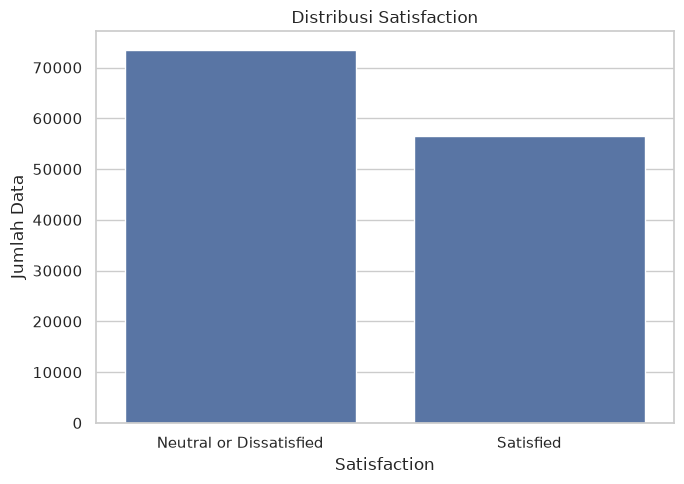

,count,percentage
Satisfaction,,
Neutral or Dissatisfied,73452,56.55
Satisfied,56428,43.45


In [11]:
# Distribusi variabel target
target_counts = df[TARGET].value_counts()
target_percentage = df[TARGET].value_counts(normalize=True) * 100

# Diagram batang
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=TARGET, order=target_counts.index)

plt.title("Distribusi Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

# Menampilkan jumlah dan persentase setiap kelas
display(pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentage.round(2)
}))

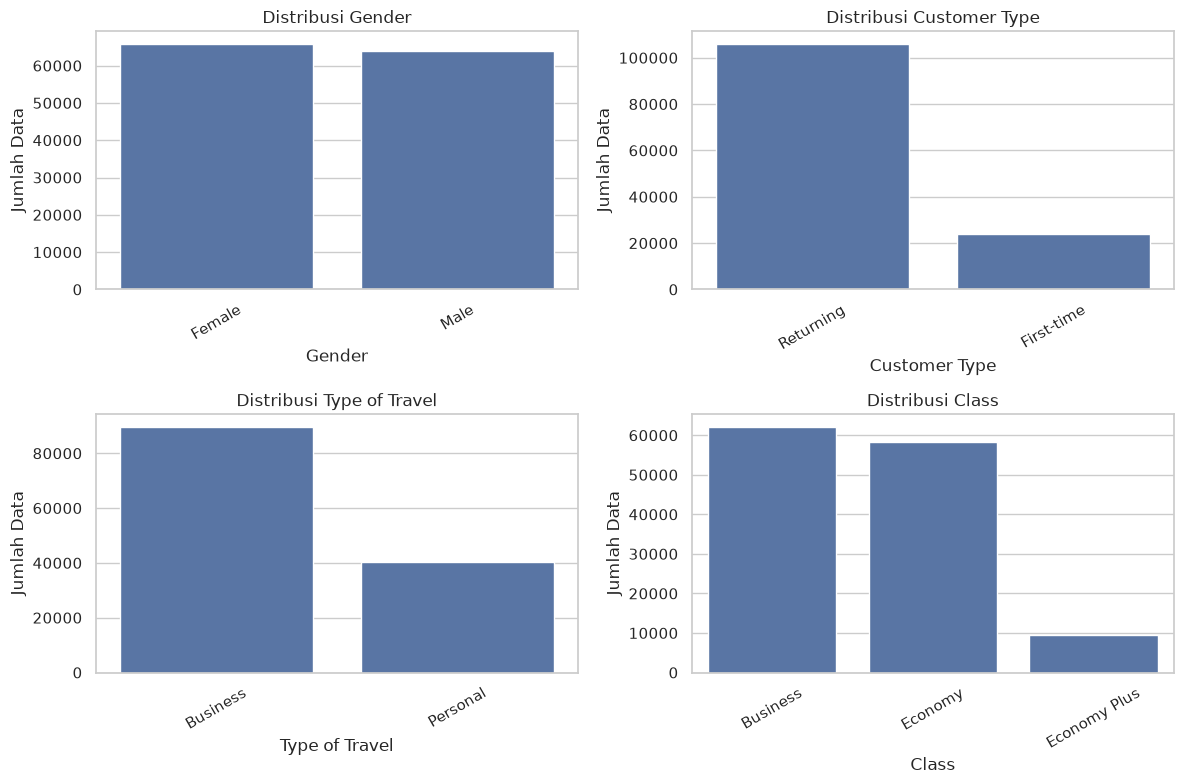

In [12]:
# Visualisasi fitur kategorikal
n_cols = 2
n_rows = (len(categorical_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(12, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribusi {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Jumlah Data")
    axes[i].tick_params(axis="x", rotation=30)

# Menghapus subplot kosong
for i in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

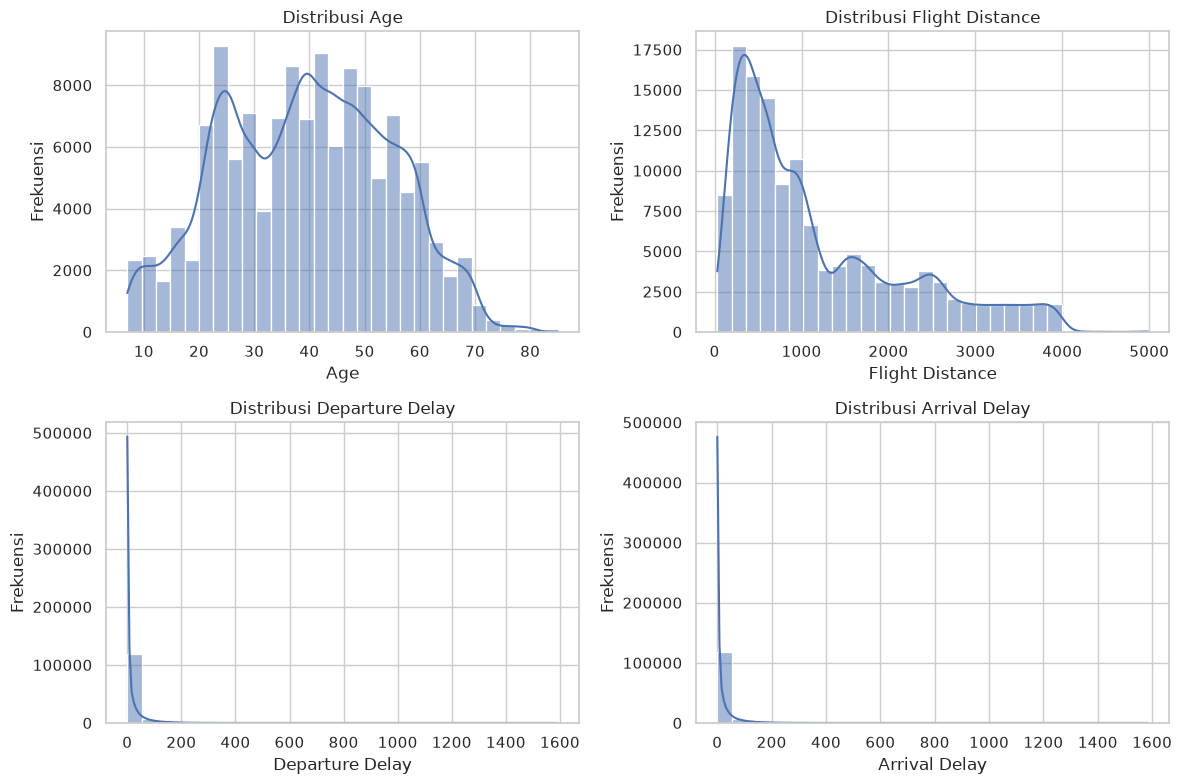

In [13]:
# Visualisasi fitur kontinu
n_cols = 2
n_rows = (len(continuous_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(12, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(continuous_features):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribusi {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frekuensi")

for i in range(len(continuous_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

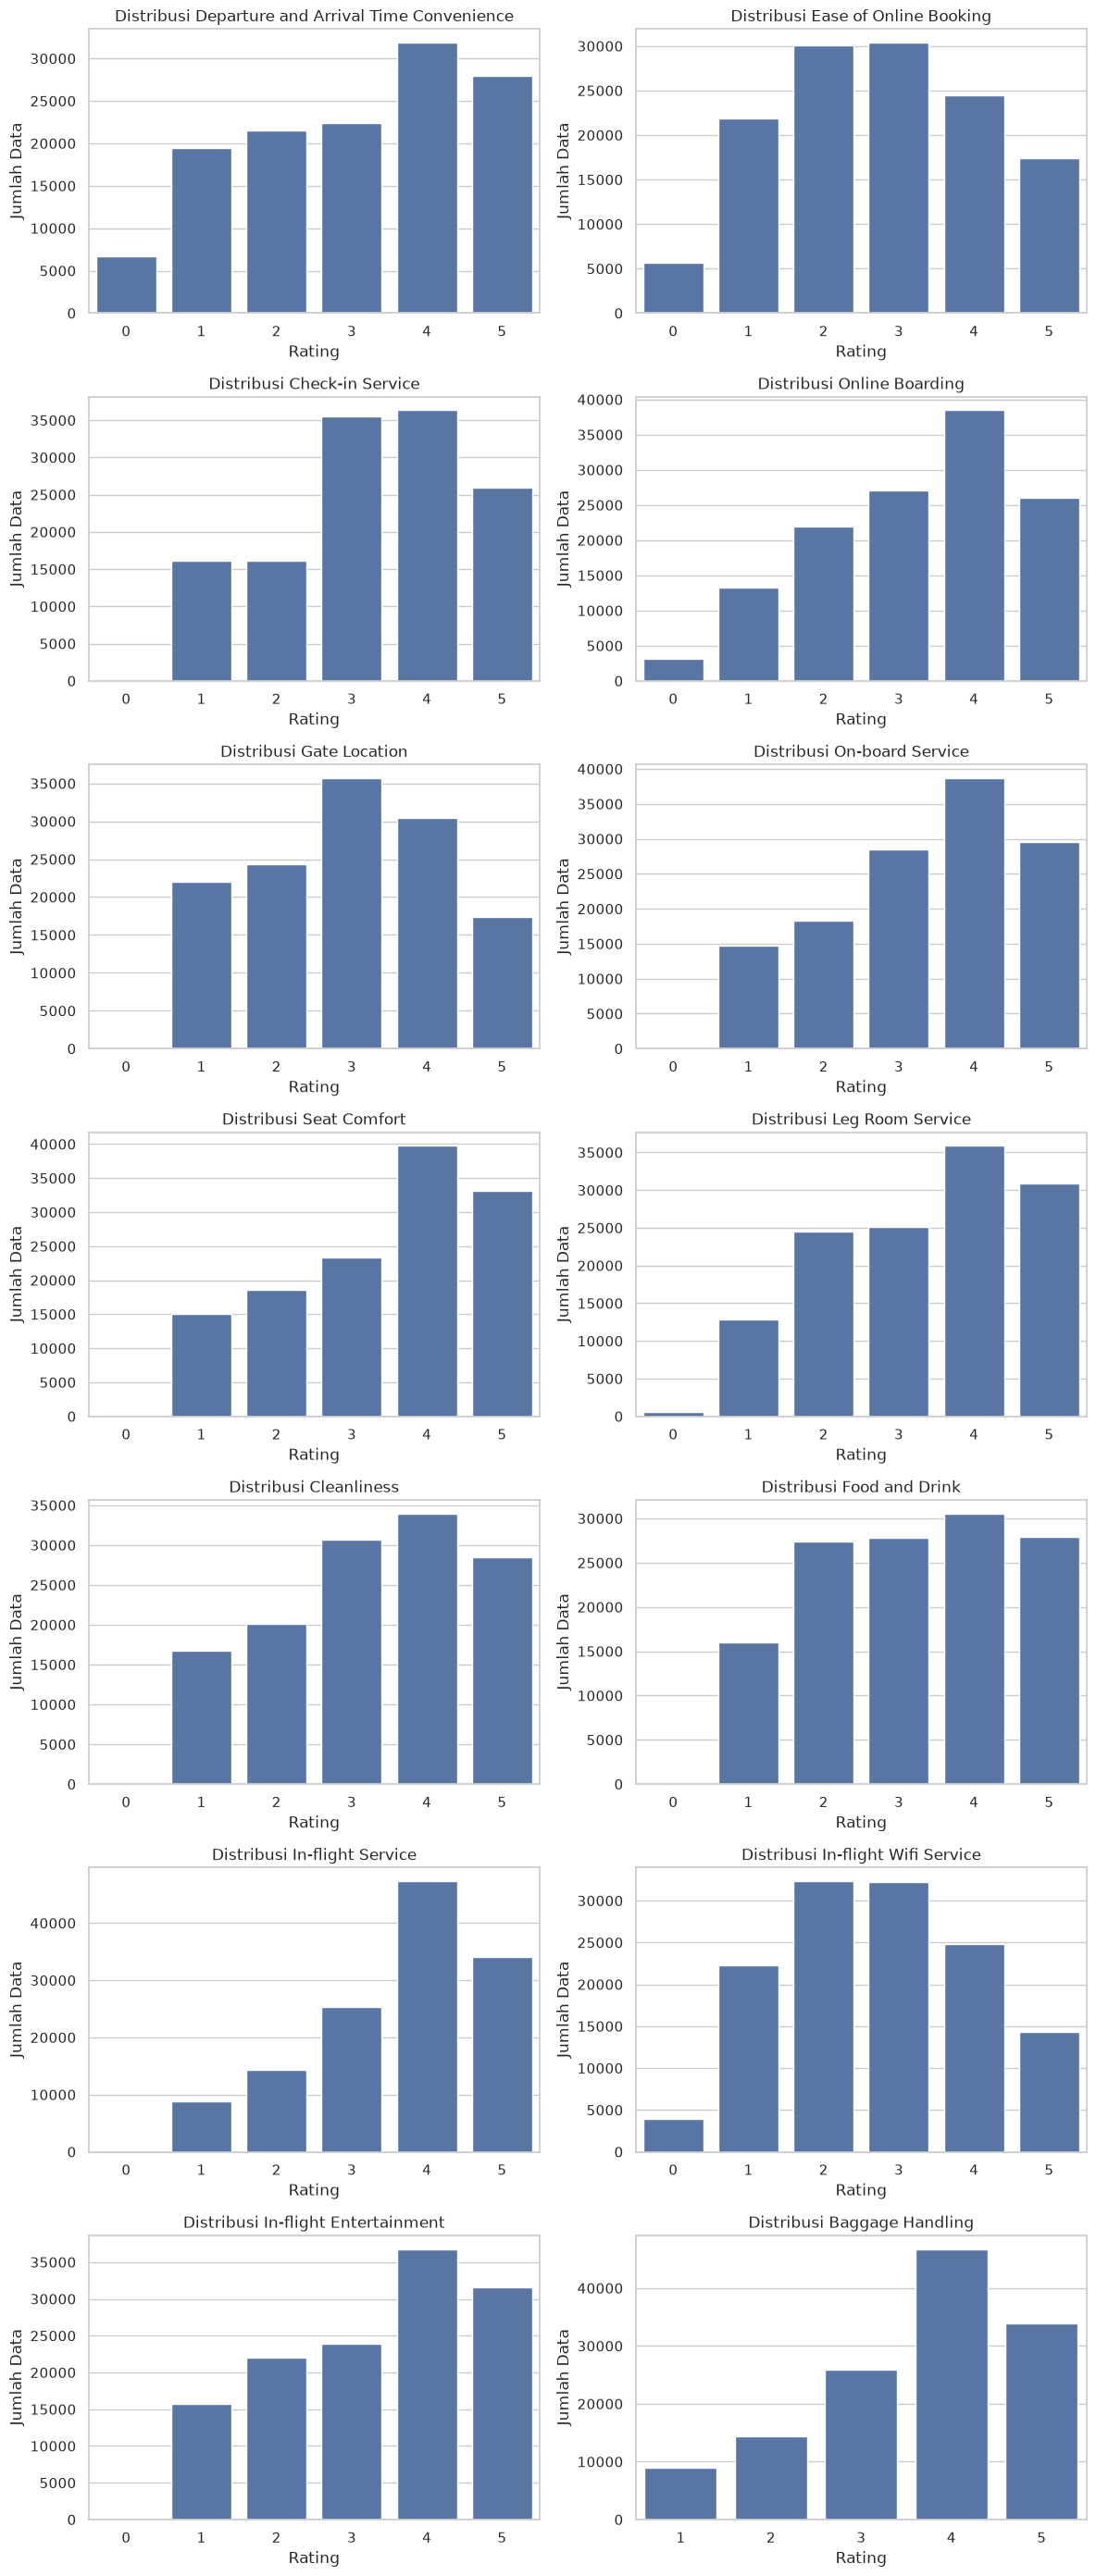

In [14]:
# Visualisasi fitur rating
n_cols = 2
n_rows = (len(rating_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(12, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(rating_features):
    sns.countplot(
        data=df,
        x=col,
        order=sorted(df[col].dropna().unique()),
        ax=axes[i]
    )

    axes[i].set_title(f"Distribusi {col}")
    axes[i].set_xlabel("Rating")
    axes[i].set_ylabel("Jumlah Data")

for i in range(len(rating_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [15]:
# Menghitung distribusi kelas target
class_counts = df[TARGET].value_counts()

majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print(f"Kelas mayoritas : {majority_class} ({majority_count})")
print(f"Kelas minoritas : {minority_class} ({minority_count})")
print(f"Imbalance ratio : {imbalance_ratio:.2f}:1")

Kelas mayoritas : Neutral or Dissatisfied (73452)
Kelas minoritas : Satisfied (56428)
Imbalance ratio : 1.30:1


Berdasarkan distribusi variabel target (Satisfaction), terdapat 73.452 data pada kelas Neutral or Dissatisfied dan 56.428 data pada kelas Satisfied. Dengan nilai imbalance ratio sebesar 1,30:1, dataset menunjukkan ketidakseimbangan kelas ringan (mild class imbalance). Perbedaan jumlah sampel antarkelas relatif kecil sehingga distribusi data masih cukup seimbang

D. Analisis outlier & korelasi: Lakukan deteksi outlier pada fitur kontinu menggunakan boxplot dan jelaskan apakah perlu ditangani, serta buat heatmap korelasi dan identifikasi hubungan antar fitur yang terkait dengan variabel lainnya.

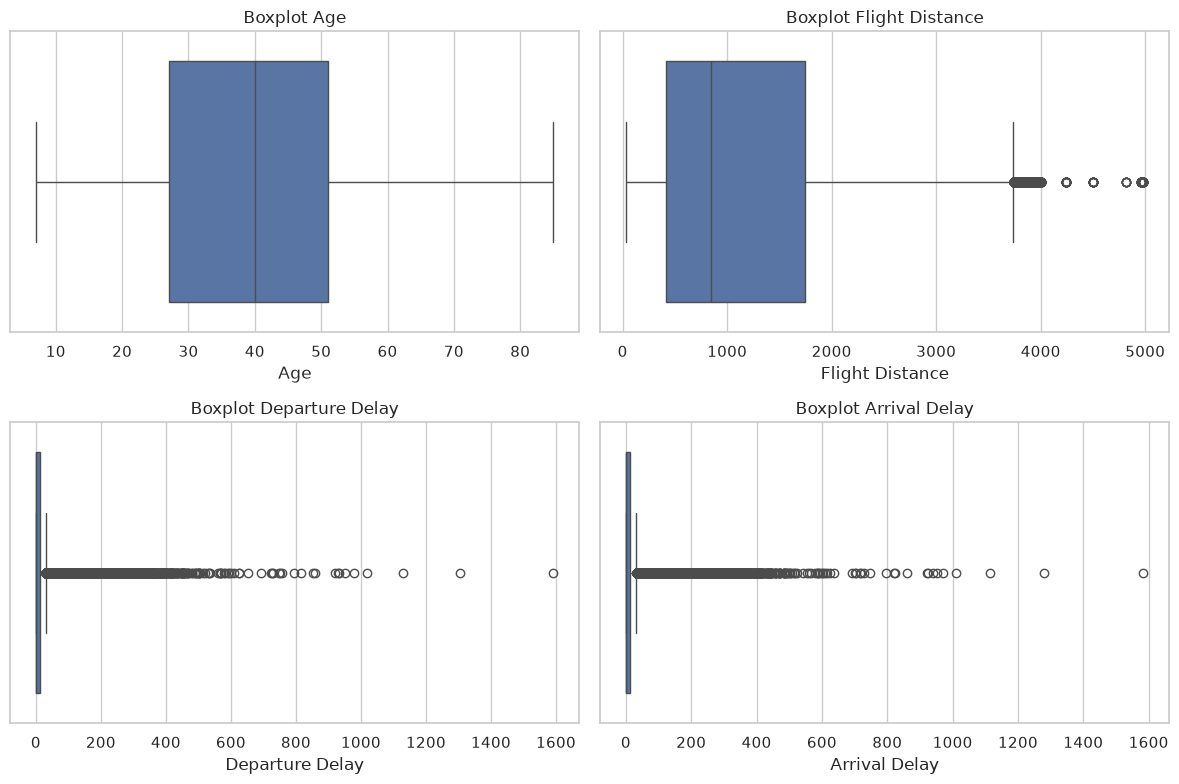

In [16]:
# Visualisasi outlier fitur kontinu
n_cols = 2
n_rows = (len(continuous_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(12, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(continuous_features):
    sns.boxplot(
        data=df,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot {col}")
    axes[i].set_xlabel(col)

for i in range(len(continuous_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [17]:
# Menghitung outlier menggunakan metode IQR
outlier_summary = []

for col in continuous_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": round(
            outlier_count / df[col].notna().sum() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,Age,-9.0,87.0,0,0.00
1,Flight Distance,-1581.0,3739.0,2855,2.20
2,Departure Delay,-18.0,30.0,18098,13.93
3,Arrival Delay,-19.5,32.5,17492,13.51


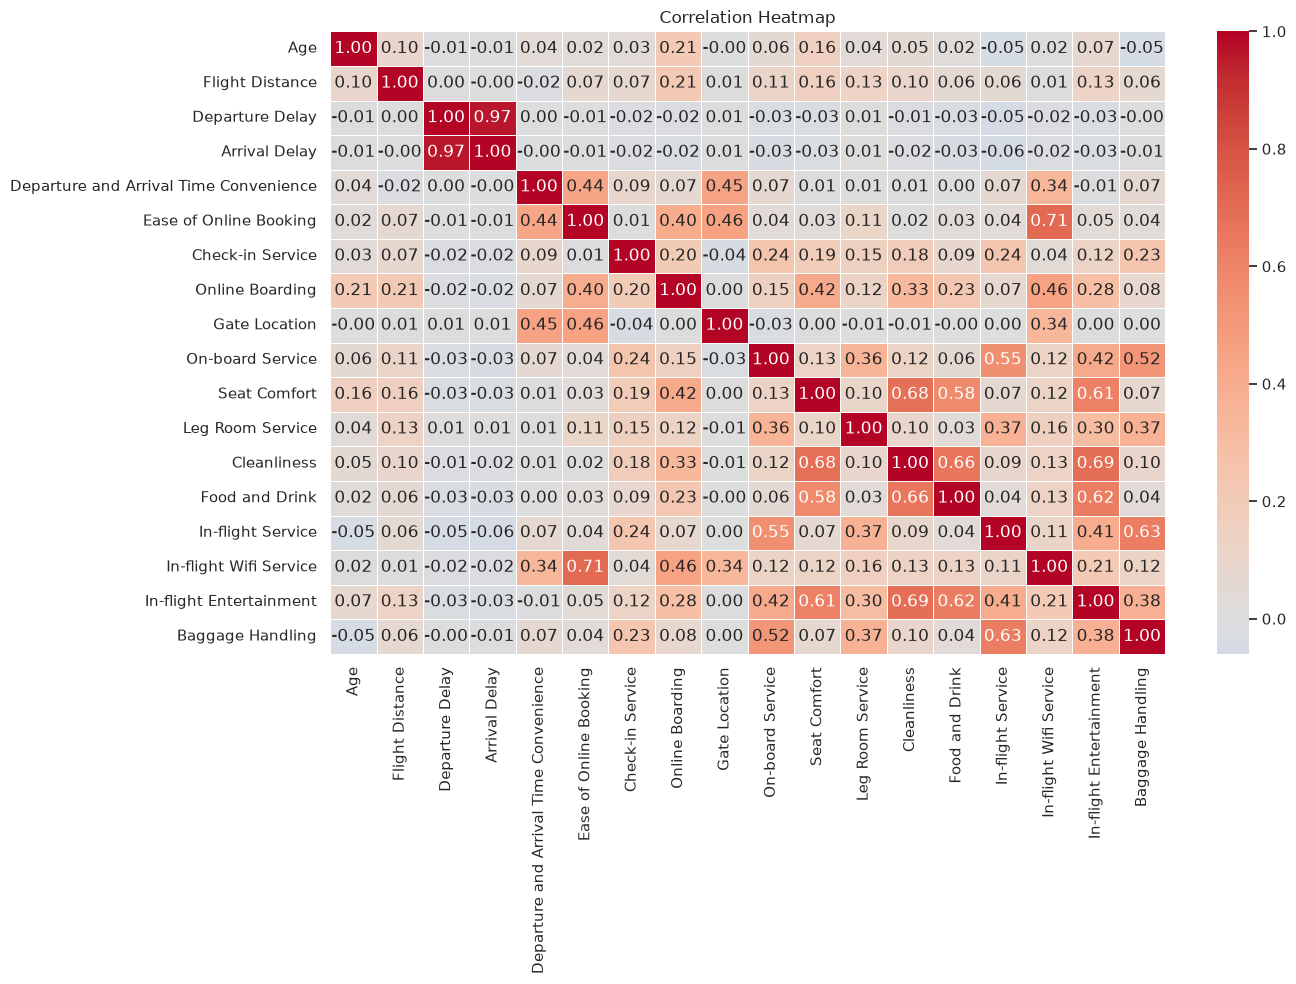

In [18]:
# Memilih fitur numerik
correlation_features = continuous_features + rating_features

# Menghitung matriks korelasi
correlation_matrix = df[correlation_features].corr(method="pearson")

# Visualisasi heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

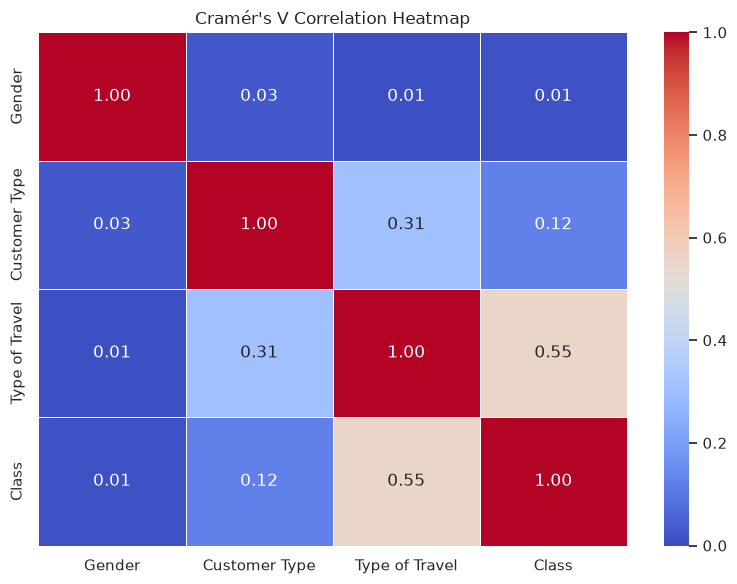

In [19]:
def cramers_v(x, y):
    contingency_table = pd.crosstab(x, y)

    chi2 = chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()

    r, k = contingency_table.shape

    phi2 = chi2 / n

    # Koreksi bias
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(k_corr - 1, r_corr - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominator)


categorical_data = df[categorical_features]

cramers_matrix = pd.DataFrame(
    np.zeros((len(categorical_features), len(categorical_features))),
    index=categorical_features,
    columns=categorical_features
)

for col1 in categorical_features:
    for col2 in categorical_features:
        cramers_matrix.loc[col1, col2] = cramers_v(
            categorical_data[col1],
            categorical_data[col2]
        )

plt.figure(figsize=(8, 6))

sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Cramér's V Correlation Heatmap")
plt.tight_layout()
plt.show()

# Direct Modeling (cuML GPU)

Sel ini mengukur persiapan matriks CPU, upload host → GPU, pelatihan GPU,
prediksi GPU, dan penyalinan prediksi kembali ke CPU secara terpisah.

A. Penentuan Variabel dan Pembagian Data: Menetapkan variabel target (y), serta menggunakan seluruh kolom lainnya sebagai fitur prediktor (X).  
B. Melakukan train–test split untuk membagi data menjadi data latih dan data uji.

In [20]:
# Menghapus seluruh baris yang memiliki missing value
df_direct = df.dropna().copy()

print(f"Jumlah data awal       : {len(df)}")
print(f"Jumlah data setelahnya : {len(df_direct)}")
print(f"Jumlah data dihapus    : {len(df) - len(df_direct)}")

# Menentukan fitur prediktor dan variabel target
X = df_direct.drop(columns=[TARGET])
y = df_direct[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"X_train: {X_train.shape}")
print(f"X_test : {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test : {y_test.shape}")

Jumlah data awal       : 129880
Jumlah data setelahnya : 129487
Jumlah data dihapus    : 393
X_train: (103589, 23)
X_test : (25898, 23)
y_train: (103589,)
y_test : (25898,)


In [21]:
# Encoding pada CPU untuk menjaga alur data awal, lalu upload sekali ke GPU.
model_categorical_features = X_train.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Fitur kategorikal:")
print(model_categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            model_categorical_features,
        )
    ],
    remainder="passthrough",
)

cpu_prepare_start = perf_counter()
X_train_encoded_cpu = dense_float32(preprocessor.fit_transform(X_train))
X_test_encoded_cpu = dense_float32(preprocessor.transform(X_test))
cpu_prepare_seconds = perf_counter() - cpu_prepare_start

# cuML bekerja paling konsisten dengan label numerik. Simpan label asli untuk plot.
direct_class_labels = np.sort(y_train.unique())
y_train_direct_cpu = np.searchsorted(
    direct_class_labels, y_train.to_numpy()
).astype(np.int32)
y_test_direct_cpu = np.searchsorted(
    direct_class_labels, y_test.to_numpy()
).astype(np.int32)

X_train_encoded, y_train_direct_gpu, train_upload_seconds = upload_to_gpu(
    X_train_encoded_cpu, y_train_direct_cpu
)
X_test_encoded, y_test_direct_gpu, test_upload_seconds = upload_to_gpu(
    X_test_encoded_cpu, y_test_direct_cpu
)

direct_transfer_timing = pd.DataFrame(
    [
        {"Stage": "Encoding + materialisasi CPU", "Seconds": cpu_prepare_seconds},
        {"Stage": "Upload data latih (CPU → GPU)", "Seconds": train_upload_seconds},
        {"Stage": "Upload data uji (CPU → GPU)", "Seconds": test_upload_seconds},
    ]
)

print(f"X_train setelah encoding: {X_train_encoded.shape}")
print(f"X_test setelah encoding : {X_test_encoded.shape}")
display(direct_transfer_timing.round(4))

Fitur kategorikal:
['Gender', 'Customer Type', 'Type of Travel', 'Class']
X_train setelah encoding: (103589, 28)
X_test setelah encoding : (25898, 28)


,Stage,Seconds
0,Encoding + materialisasi CPU,0.1048
1,Upload data latih (CPU → GPU),0.0079
2,Upload data uji (CPU → GPU),0.0019


C. Pemodelan Awal: Latih Logistic Regression, LinearSVC, dan Random Forest
dengan cuML. Data sudah berada di GPU sebelum sel ini dimulai.

In [22]:
models = {
    "Logistic Regression": cuLogisticRegression(
        max_iter=50_000,
        tol=1e-3,
        output_type="cupy",
    ),
    "SVM": cuLinearSVC(
        loss="squared_hinge",
        max_iter=10_000,
        output_type="cupy",
    ),
    "Random Forest": cuRandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        output_type="cupy",
    ),
}

trained_models, predictions, direct_model_timing = fit_predict_gpu(
    models,
    X_train_encoded,
    y_train_direct_gpu,
    X_test_encoded,
)

display(direct_model_timing.round(4))

[2026-11-10 06:21:41.437] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
Logistic Regression selesai dilatih dalam 0.220 detik.
[2026-11-10 06:21:41.469] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
SVM selesai dilatih dalam 0.029 detik.
Random Forest selesai dilatih dalam 3.255 detik.


,Model,Fit GPU (s),Predict GPU (s),GPU → CPU (s),Total model (s)
0,Logistic Regression,0.2202,0.0035,0.0001,0.2238
1,SVM,0.0285,0.0014,0.0001,0.0300
2,Random Forest,3.2554,0.0101,0.0001,3.2656


D. Evaluasi Model: Mengevaluasi performa model menggunakan matrix accuracy, precision, recall, F1-score, serta menyajikan confusion matrix.

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.964901,0.965140,0.964901,0.964828
1,Logistic Regression,0.565604,0.630185,0.565604,0.408933
2,SVM,0.565604,0.630185,0.565604,0.408933


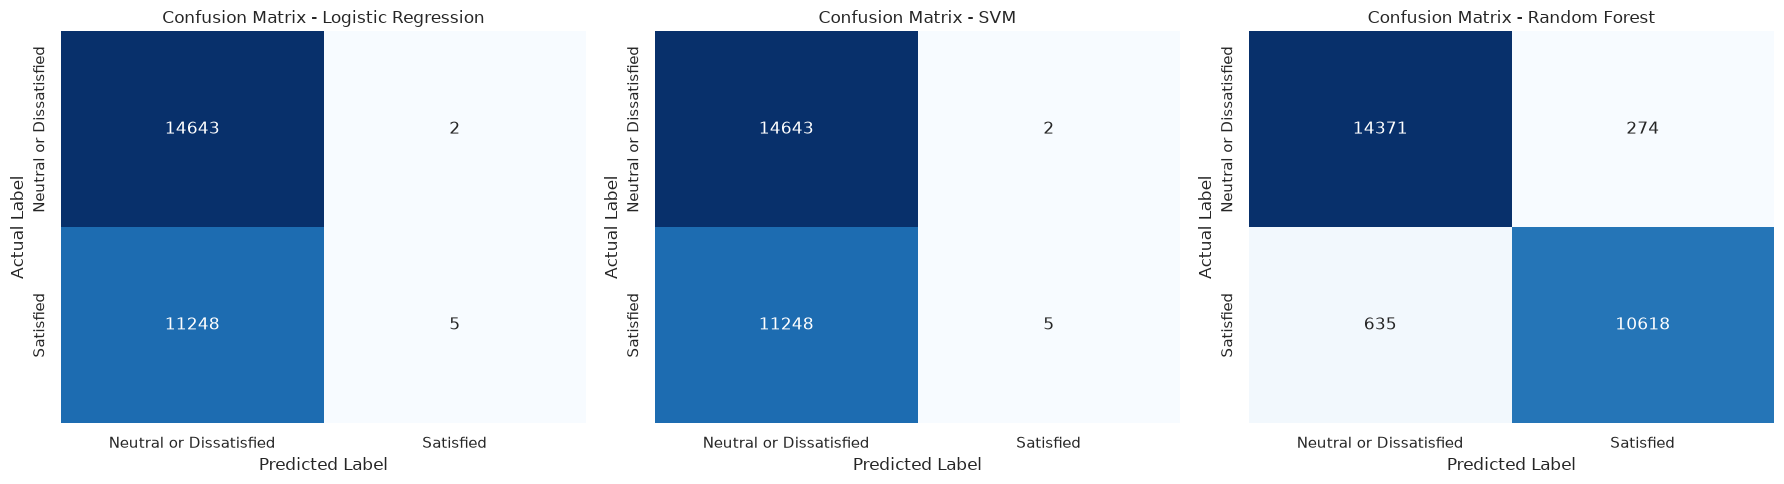

In [23]:
evaluation_results = []

for name, y_pred in predictions.items():
    evaluation_results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test_direct_cpu, y_pred),
            "Precision": precision_score(
                y_test_direct_cpu, y_pred, average="weighted", zero_division=0
            ),
            "Recall": recall_score(
                y_test_direct_cpu, y_pred, average="weighted", zero_division=0
            ),
            "F1-Score": f1_score(
                y_test_direct_cpu, y_pred, average="weighted", zero_division=0
            ),
        }
    )

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, len(trained_models), figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test_direct_cpu, y_pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=direct_class_labels,
        yticklabels=direct_class_labels,
        ax=ax,
        cbar=False,
    )
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Data Preparation (Preprocessing Data)

A. Transformasi awal: Hapus fitur yang tidak relevan dan lakukan encoding pada variabel target.

In [24]:
# Membuat salinan dataset untuk preprocessing
df_prepared = df.drop(columns=[ID_COLUMN]).copy()

# Encoding variabel target Satisfaction
df_prepared[TARGET] = df_prepared[TARGET].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})

# Menampilkan hasil encoding target
print("Distribusi target setelah encoding:")
display(df_prepared[TARGET].value_counts().sort_index())

# Menampilkan struktur dataset
print(f"\nUkuran dataset: {df_prepared.shape}")
display(df_prepared.head())

Distribusi target setelah encoding:


Satisfaction
0    73452
1    56428
Name: count, dtype: int64


Ukuran dataset: (129880, 23)


,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,Male,48,First-time,Business,Business,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5,0
1,Female,35,Returning,Business,Business,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5,1
2,Male,41,Returning,Business,Business,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3,1
3,Male,50,Returning,Business,Business,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5,1
4,Female,49,Returning,Business,Business,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3,1


B. Penanganan missing value: Lakukan imputasi pada fitur yang memiliki missing value menggunakan metode yang sesuai. Jelaskan alasan pemilihan metode yang digunakan. Selain itu, dilakukan analisis outlier untuk mengidentifikasi nilai-nilai ekstrim yang dapat mempengaruhi performa model.

In [25]:
# Memeriksa missing value
missing_summary = pd.DataFrame({
    "Missing Values": df_prepared.isna().sum(),
    "Missing Percentage": (
        df_prepared.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary[missing_summary["Missing Values"] > 0]
)

,Missing Values,Missing Percentage
Arrival Delay,393,0.3


In [26]:
# Menentukan fitur prediktor dan target
X_prepared = df_prepared.drop(columns=[TARGET])
y_prepared = df_prepared[TARGET]

# Membagi data latih dan data uji
X_train_prep, X_test_prep, y_train_prep, y_test_prep = train_test_split(
    X_prepared,
    y_prepared,
    test_size=0.2,
    random_state=42,
    stratify=y_prepared
)

print(f"X_train: {X_train_prep.shape}")
print(f"X_test : {X_test_prep.shape}")
print(f"y_train: {y_train_prep.shape}")
print(f"y_test : {y_test_prep.shape}")

X_train: (103904, 22)
X_test : (25976, 22)
y_train: (103904,)
y_test : (25976,)


In [27]:
# Mengidentifikasi fitur numerik yang memiliki missing value
numeric_missing_features = [
    col for col in X_train_prep.select_dtypes(include="number").columns
    if X_train_prep[col].isna().any()
]

# Membuat salinan data
X_train_prep_clean = X_train_prep.copy()
X_test_prep_clean = X_test_prep.copy()

# Imputasi menggunakan median
imputer = SimpleImputer(strategy="median")

X_train_prep_clean[numeric_missing_features] = imputer.fit_transform(
    X_train_prep[numeric_missing_features]
)

X_test_prep_clean[numeric_missing_features] = imputer.transform(
    X_test_prep[numeric_missing_features]
)

# Memeriksa hasil imputasi
print("Missing value setelah imputasi:")
print("Data latih :", X_train_prep_clean.isna().sum().sum())
print("Data uji   :", X_test_prep_clean.isna().sum().sum())

Missing value setelah imputasi:
Data latih : 0
Data uji   : 0


In [28]:
outlier_summary = []

for col in continuous_features:
    data = X_train_prep[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (data < lower_bound) | (data > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(
            outlier_count / len(data) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.sort_values(
        by="Outlier Percentage",
        ascending=False
    ).reset_index(drop=True)
)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Departure Delay,-18.0,30.0,14476,13.93
1,Arrival Delay,-19.5,32.5,13961,13.48
2,Flight Distance,-1581.0,3739.0,2281,2.20
3,Age,-9.0,87.0,0,0.00


C. Encoding & Scaling: Terapkan encoding dan lakukan scaling.

In [29]:
# Mengidentifikasi fitur kategorikal
categorical_features_prep = X_train_prep_clean.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

# Mengidentifikasi fitur numerik
numeric_features_prep = X_train_prep_clean.select_dtypes(
    include="number"
).columns.tolist()

print("Fitur kategorikal:")
print(categorical_features_prep)

print("\nFitur numerik:")
print(numeric_features_prep)

Fitur kategorikal:
['Gender', 'Customer Type', 'Type of Travel', 'Class']

Fitur numerik:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']


In [30]:
# Transformasi dilakukan pada CPU agar biaya integrasi CPU → GPU dapat diukur.
robust_features_prep = ["Departure Delay", "Arrival Delay"]
standard_features_prep = [
    col for col in numeric_features_prep if col not in robust_features_prep
]

preprocessor_prep = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_prep,
        ),
        ("robust", RobustScaler(), robust_features_prep),
        ("standard", StandardScaler(), standard_features_prep),
    ]
)

cpu_prepare_start = perf_counter()
X_train_prep_transformed_cpu = dense_float32(
    preprocessor_prep.fit_transform(X_train_prep_clean)
)
X_test_prep_transformed_cpu = dense_float32(
    preprocessor_prep.transform(X_test_prep_clean)
)
cpu_prepare_seconds = perf_counter() - cpu_prepare_start

y_train_prep_cpu = y_train_prep.to_numpy(dtype=np.int32)
y_test_prep_cpu = y_test_prep.to_numpy(dtype=np.int32)

(
    X_train_prep_transformed,
    y_train_prep_gpu,
    train_upload_seconds,
) = upload_to_gpu(X_train_prep_transformed_cpu, y_train_prep_cpu)
(
    X_test_prep_transformed,
    y_test_prep_gpu,
    test_upload_seconds,
) = upload_to_gpu(X_test_prep_transformed_cpu, y_test_prep_cpu)

preprocessing_transfer_timing = pd.DataFrame(
    [
        {"Stage": "Preprocessing + materialisasi CPU", "Seconds": cpu_prepare_seconds},
        {"Stage": "Upload data latih (CPU → GPU)", "Seconds": train_upload_seconds},
        {"Stage": "Upload data uji (CPU → GPU)", "Seconds": test_upload_seconds},
    ]
)

print("Ukuran data setelah encoding dan scaling:")
print(f"X_train: {X_train_prep_transformed.shape}")
print(f"X_test : {X_test_prep_transformed.shape}")
display(preprocessing_transfer_timing.round(4))

Ukuran data setelah encoding dan scaling:
X_train: (103904, 27)
X_test : (25976, 27)


,Stage,Seconds
0,Preprocessing + materialisasi CPU,0.1353
1,Upload data latih (CPU → GPU),0.0029
2,Upload data uji (CPU → GPU),0.0009


# Validasi & Sampling (Imbalance Data)

A. Penanganan imbalance class: Jika ditemukan ketidakseimbangan pada variabel satisfaction, lakukan penanganan (misal menggunakan SMOTE atau Random Oversampling).
B. Pemodelan ulang: Latih ulang model klasifikasi pilihan Anda menggunakan data yang telah melalui proses sampling dan preprocessing.

In [31]:
models_prep = {
    "Logistic Regression": cuLogisticRegression(
        max_iter=10_000,
        output_type="cupy",
    ),
    "SVM": cuLinearSVC(
        loss="squared_hinge",
        max_iter=10_000,
        output_type="cupy",
    ),
    "Random Forest": cuRandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        output_type="cupy",
    ),
}

trained_models_prep, predictions_prep, preprocessing_model_timing = fit_predict_gpu(
    models_prep,
    X_train_prep_transformed,
    y_train_prep_gpu,
    X_test_prep_transformed,
)

display(preprocessing_model_timing.round(4))

Logistic Regression selesai dilatih dalam 0.021 detik.
SVM selesai dilatih dalam 0.015 detik.
Random Forest selesai dilatih dalam 3.183 detik.


,Model,Fit GPU (s),Predict GPU (s),GPU → CPU (s),Total model (s)
0,Logistic Regression,0.0214,0.0006,0.0001,0.0220
1,SVM,0.0152,0.0009,0.0001,0.0162
2,Random Forest,3.1834,0.0024,0.0001,3.1859


C. Evaluasi Sampling: Bandingkan matrik evaluasi untuk kelas 'Satisfied' dari model sebelum dan sesudah dilakukan penanganan imbalance.

In [32]:
evaluation_results_prep = []

for name, y_pred in predictions_prep.items():
    evaluation_results_prep.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test_prep_cpu, y_pred),
            "Precision": precision_score(
                y_test_prep_cpu, y_pred, average="weighted", zero_division=0
            ),
            "Recall": recall_score(
                y_test_prep_cpu, y_pred, average="weighted", zero_division=0
            ),
            "F1-Score": f1_score(
                y_test_prep_cpu, y_pred, average="weighted", zero_division=0
            ),
        }
    )

evaluation_prep_df = pd.DataFrame(evaluation_results_prep)
display(
    evaluation_prep_df.sort_values(by="F1-Score", ascending=False).reset_index(
        drop=True
    )
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.963967,0.964229,0.963967,0.963889
1,Logistic Regression,0.877117,0.876972,0.877117,0.876839
2,SVM,0.875731,0.875608,0.875731,0.875413


D. Bandingkan direct modeling dengan yang sudah di oversampling dan preprocessing.

In [33]:
# Menggabungkan hasil evaluasi kedua eksperimen
comparison_df = evaluation_df.merge(
    evaluation_prep_df,
    on="Model",
    suffixes=("_Direct", "_Preprocessing")
)

# Menghitung perubahan performa
for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    comparison_df[f"{metric}_Difference"] = (
        comparison_df[f"{metric}_Preprocessing"]
        - comparison_df[f"{metric}_Direct"]
    )

display(comparison_df.round(4))

,Model,Accuracy_Direct,Precision_Direct,Recall_Direct,F1-Score_Direct,Accuracy_Preprocessing,Precision_Preprocessing,Recall_Preprocessing,F1-Score_Preprocessing,Accuracy_Difference,Precision_Difference,Recall_Difference,F1-Score_Difference
0,Logistic Regression,0.5656,0.6302,0.5656,0.4089,0.8771,0.8770,0.8771,0.8768,0.3115,0.2468,0.3115,0.4679
1,SVM,0.5656,0.6302,0.5656,0.4089,0.8757,0.8756,0.8757,0.8754,0.3101,0.2454,0.3101,0.4665
2,Random Forest,0.9649,0.9651,0.9649,0.9648,0.9640,0.9642,0.9640,0.9639,-0.0009,-0.0009,-0.0009,-0.0009


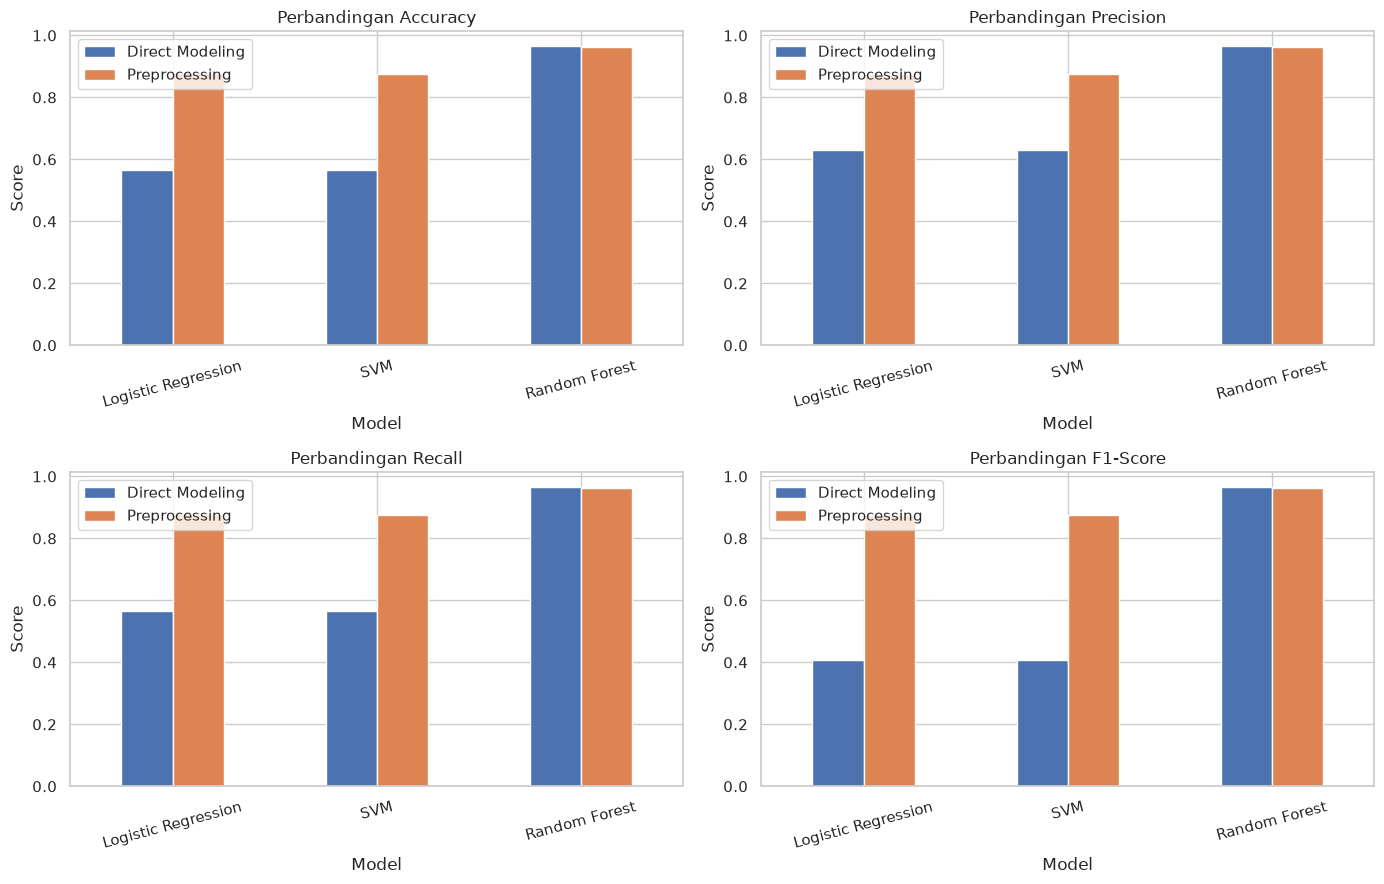

In [34]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

axes = axes.flatten()

for i, metric in enumerate(metrics):
    comparison_df.plot(
        x="Model",
        y=[f"{metric}_Direct", f"{metric}_Preprocessing"],
        kind="bar",
        ax=axes[i],
        rot=15
    )

    axes[i].set_title(f"Perbandingan {metric}")
    axes[i].set_xlabel("Model")
    axes[i].set_ylabel("Score")
    axes[i].legend(
        ["Direct Modeling", "Preprocessing"],
        loc="best"
    )

plt.tight_layout()
plt.show()

# Hyperparameter dan Feature Selection (Optimasi)

A. Feature selection: Lakukan analisis feature importance pada data untuk menentukan fitur mana yang paling berpengaruh terhadap kepuasan pelanggan.

In [35]:
rf_model = trained_models_prep["Random Forest"]
feature_names = preprocessor_prep.get_feature_names_out()
feature_importances = rf_model.feature_importances_

if hasattr(feature_importances, "get"):
    feature_importances = feature_importances.get()

feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": np.asarray(feature_importances)}
).sort_values(by="Importance", ascending=False).reset_index(drop=True)

display(feature_importance_df)

,Feature,Importance
0,standard__Online Boarding,0.169344
1,standard__In-flight Wifi Service,0.140183
2,categorical__Class_Business,0.079605
3,categorical__Type of Travel_Personal,0.057799
4,standard__In-flight Entertainment,0.055538
5,categorical__Type of Travel_Business,0.047064
6,standard__Seat Comfort,0.045193
7,categorical__Class_Economy,0.039403
8,standard__Ease of Online Booking,0.034914
9,standard__On-board Service,0.033223


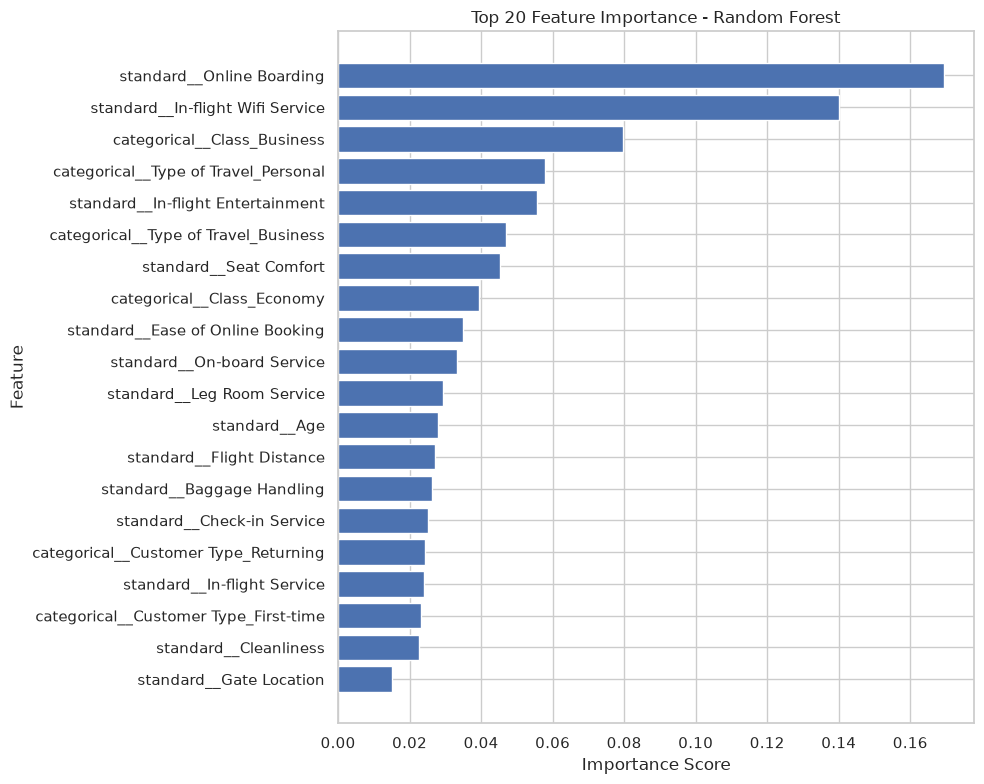

In [36]:
top_features = feature_importance_df.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.title("Top 20 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

B. Hyperparameter Tuning: data hasil preprocessing telah di-upload sekali pada
sel sebelumnya. Grid search di bawah mempertahankan seluruh data dan fold di
GPU sehingga waktu tuning tidak memasukkan upload berulang untuk setiap fold.
Waktu total tetap mencakup slicing GPU, fit, prediksi, dan perhitungan F1.

n_jobs=-1 tidak dipakai karena beberapa proses Grid Search CPU yang memakai
satu GPU yang sama akan berebut VRAM. Tuning dijalankan berurutan pada satu GPU.

Logistic Regression (cuML)

In [37]:
def run_gpu_grid_search(model_factory, parameter_grid, x_gpu, y_gpu, y_cpu, name):
    """Run a reproducible 5-fold GPU grid search without repeated host uploads."""
    splitter = StratifiedKFold(n_splits=5, shuffle=False)
    gpu_folds = [
        (cp.asarray(train_idx), cp.asarray(valid_idx), valid_idx)
        for train_idx, valid_idx in splitter.split(np.zeros(len(y_cpu)), y_cpu)
    ]
    candidates = list(ParameterGrid(parameter_grid))
    print(f"Fitting 5 folds for each of {len(candidates)} candidates, "
          f"totalling {len(candidates) * len(gpu_folds)} fits")

    all_started = perf_counter()
    rows = []
    best_score = -np.inf
    best_params = None

    for candidate_number, params in enumerate(candidates, start=1):
        candidate_started = perf_counter()
        fold_scores = []

        for train_idx_gpu, valid_idx_gpu, valid_idx_cpu in gpu_folds:
            model = model_factory(**params)
            _, _ = timed_gpu_call(
                lambda model=model, train_idx_gpu=train_idx_gpu: model.fit(
                    x_gpu[train_idx_gpu], y_gpu[train_idx_gpu]
                )
            )
            prediction_gpu, _ = timed_gpu_call(
                lambda model=model, valid_idx_gpu=valid_idx_gpu: model.predict(
                    x_gpu[valid_idx_gpu]
                )
            )
            prediction_cpu, _ = copy_prediction_to_cpu(prediction_gpu)
            fold_scores.append(
                f1_score(y_cpu[valid_idx_cpu], prediction_cpu, zero_division=0)
            )

        mean_score = float(np.mean(fold_scores))
        candidate_seconds = perf_counter() - candidate_started
        rows.append(
            {
                "Candidate": candidate_number,
                "Parameters": params,
                "Mean CV F1": mean_score,
                "Candidate time (s)": candidate_seconds,
            }
        )
        if mean_score > best_score:
            best_score = mean_score
            best_params = params

    best_estimator = model_factory(**best_params)
    _, refit_seconds = timed_gpu_call(
        lambda: best_estimator.fit(x_gpu, y_gpu)
    )
    total_seconds = perf_counter() - all_started
    result_table = pd.DataFrame(rows).sort_values(
        "Mean CV F1", ascending=False
    ).reset_index(drop=True)

    print(f"{name} best parameters: {best_params}")
    print(f"{name} best CV F1-Score: {best_score:.6f}")
    print(f"{name} total tuning time: {total_seconds:.3f} detik")

    return {
        "best_estimator": best_estimator,
        "best_params": best_params,
        "best_score": best_score,
        "cv_results": result_table,
        "refit_seconds": refit_seconds,
        "total_seconds": total_seconds,
    }


def make_logistic_regression(**params):
    return cuLogisticRegression(
        max_iter=10_000,
        tol=1e-3,
        solver="qn",
        output_type="cupy",
        **params,
    )


# cuML hanya menyediakan solver quasi-Newton. Ruang pencarian tetap 48 kandidat,
# tetapi l1_ratio diterapkan secara benar melalui penalty="elasticnet".
param_grid_lr = [
    {
        "penalty": ["l2"],
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "class_weight": [None, "balanced"],
    },
    {
        "penalty": ["elasticnet"],
        "l1_ratio": [0, 0.5, 1],
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "class_weight": [None, "balanced"],
    },
]

grid_lr = run_gpu_grid_search(
    make_logistic_regression,
    param_grid_lr,
    X_train_prep_transformed,
    y_train_prep_gpu,
    y_train_prep_cpu,
    "Logistic Regression",
)
display(grid_lr["cv_results"].head(10))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
[2026-11-10 06:21:50.859] [CUML] [warning] QWL-QN stopped, because the line search failed to advance (step delta = 0.000000)
[2026-11-10 06:21:51.711] [CUML] [warning] QWL-QN stopped, because the line search failed to advance (step delta = 0.000000)
[2026-11-10 06:21:53.488] [CUML] [warning] QWL-QN stopped, because the line search failed to advance (step delta = 0.000000)
Logistic Regression best parameters: {'C': 0.1, 'class_weight': None, 'l1_ratio': 1, 'penalty': 'elasticnet'}
Logistic Regression best CV F1-Score: 0.851683
Logistic Regression total tuning time: 6.474 detik


,Candidate,Parameters,Mean CV F1,Candidate time (s)
0,27,"{'C': 0.1, 'class_weight': None, 'l1_ratio': 1...",0.851683,0.091056
1,26,"{'C': 0.1, 'class_weight': None, 'l1_ratio': 0...",0.851621,0.095277
2,32,"{'C': 1, 'class_weight': None, 'l1_ratio': 0.5...",0.851567,0.087000
3,5,"{'C': 0.1, 'class_weight': None, 'penalty': 'l2'}",0.851537,0.089661
4,25,"{'C': 0.1, 'class_weight': None, 'l1_ratio': 0...",0.851537,0.094221
5,44,"{'C': 100, 'class_weight': None, 'l1_ratio': 0...",0.851473,0.087316
6,45,"{'C': 100, 'class_weight': None, 'l1_ratio': 1...",0.851470,0.084364
7,33,"{'C': 1, 'class_weight': None, 'l1_ratio': 1, ...",0.851464,0.087268
8,31,"{'C': 1, 'class_weight': None, 'l1_ratio': 0, ...",0.851454,0.086460
9,7,"{'C': 1, 'class_weight': None, 'penalty': 'l2'}",0.851454,0.089997


LinearSVC (cuML)

In [38]:
def make_linear_svc(**params):
    return cuLinearSVC(
        max_iter=10_000,
        output_type="cupy",
        **params,
    )


param_grid_svm = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "loss": ["hinge", "squared_hinge"],
    "class_weight": [None, "balanced"],
}

grid_svm = run_gpu_grid_search(
    make_linear_svc,
    param_grid_svm,
    X_train_prep_transformed,
    y_train_prep_gpu,
    y_train_prep_cpu,
    "LinearSVC",
)
display(grid_svm["cv_results"].head(10))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
LinearSVC best parameters: {'C': 0.1, 'class_weight': 'balanced', 'loss': 'hinge'}
LinearSVC best CV F1-Score: 0.852674
LinearSVC total tuning time: 3.190 detik


,Candidate,Parameters,Mean CV F1,Candidate time (s)
0,11,"{'C': 0.1, 'class_weight': 'balanced', 'loss':...",0.852674,0.176120
1,15,"{'C': 1, 'class_weight': 'balanced', 'loss': '...",0.852655,0.148902
2,7,"{'C': 0.01, 'class_weight': 'balanced', 'loss'...",0.852655,0.243484
3,23,"{'C': 100, 'class_weight': 'balanced', 'loss':...",0.852646,0.154640
4,19,"{'C': 10, 'class_weight': 'balanced', 'loss': ...",0.852563,0.191423
5,3,"{'C': 0.001, 'class_weight': 'balanced', 'loss...",0.852370,0.199724
6,13,"{'C': 1, 'class_weight': None, 'loss': 'hinge'}",0.852076,0.152266
7,21,"{'C': 100, 'class_weight': None, 'loss': 'hinge'}",0.852050,0.138229
8,9,"{'C': 0.1, 'class_weight': None, 'loss': 'hinge'}",0.852033,0.150179
9,17,"{'C': 10, 'class_weight': None, 'loss': 'hinge'}",0.852017,0.162589


Random Forest (cuML)

In [39]:
def make_random_forest(**params):
    return cuRandomForestClassifier(
        random_state=RANDOM_STATE,
        output_type="cupy",
        **params,
    )


param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid_rf = run_gpu_grid_search(
    make_random_forest,
    param_grid_rf,
    X_train_prep_transformed,
    y_train_prep_gpu,
    y_train_prep_cpu,
    "Random Forest",
)
display(grid_rf["cv_results"].head(10))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Random Forest best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest best CV F1-Score: 0.956787
Random Forest total tuning time: 267.019 detik


,Candidate,Parameters,Mean CV F1,Candidate time (s)
0,2,"{'max_depth': None, 'min_samples_leaf': 1, 'mi...",0.956787,26.359291
1,6,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.956544,26.911268
2,4,"{'max_depth': None, 'min_samples_leaf': 1, 'mi...",0.956509,21.668243
3,1,"{'max_depth': None, 'min_samples_leaf': 1, 'mi...",0.956460,12.981046
4,10,"{'max_depth': 20, 'min_samples_leaf': 1, 'min_...",0.956378,21.251748
5,8,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.956314,21.028094
6,3,"{'max_depth': None, 'min_samples_leaf': 1, 'mi...",0.956306,10.613673
7,9,"{'max_depth': 20, 'min_samples_leaf': 1, 'min_...",0.956252,10.438300
8,7,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.956131,10.336984
9,5,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.956048,13.224502


Evaluasi model

In [40]:
best_models = {
    "Logistic Regression": grid_lr["best_estimator"],
    "SVM": grid_svm["best_estimator"],
    "Random Forest": grid_rf["best_estimator"],
}

predictions_tuned = {}
tuned_prediction_timing = []

for name, model in best_models.items():
    prediction_gpu, predict_seconds = timed_gpu_call(
        lambda model=model: model.predict(X_test_prep_transformed)
    )
    prediction_cpu, download_seconds = copy_prediction_to_cpu(prediction_gpu)
    predictions_tuned[name] = prediction_cpu
    tuned_prediction_timing.append(
        {
            "Model": name,
            "Predict GPU (s)": predict_seconds,
            "GPU → CPU (s)": download_seconds,
        }
    )

display(pd.DataFrame(tuned_prediction_timing).round(4))

,Model,Predict GPU (s),GPU → CPU (s)
0,Logistic Regression,0.0010,0.0001
1,SVM,0.0005,0.0001
2,Random Forest,0.0037,0.0001


In [41]:
evaluation_results_tuned = []

for name, y_pred in predictions_tuned.items():
    evaluation_results_tuned.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test_prep_cpu, y_pred),
            "Precision": precision_score(
                y_test_prep_cpu, y_pred, average="weighted", zero_division=0
            ),
            "Recall": recall_score(
                y_test_prep_cpu, y_pred, average="weighted", zero_division=0
            ),
            "F1-Score": f1_score(
                y_test_prep_cpu, y_pred, average="weighted", zero_division=0
            ),
        }
    )

evaluation_tuned_df = pd.DataFrame(evaluation_results_tuned)
display(
    evaluation_tuned_df.sort_values(by="F1-Score", ascending=False).reset_index(
        drop=True
    )
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.964159,0.964414,0.964159,0.964083
1,Logistic Regression,0.877194,0.877052,0.877194,0.876913
2,SVM,0.875077,0.875066,0.875077,0.875071


C. Visualisasi perbandingan: Bandingkan hasil evaluasi model, sebelum dan sesudah penerapan optimasi menggunakan visualisasi. 

In [42]:
comparison_tuning_df = evaluation_prep_df.merge(
    evaluation_tuned_df,
    on="Model",
    suffixes=("_Before", "_After")
)

for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    comparison_tuning_df[f"{metric}_Difference"] = (
        comparison_tuning_df[f"{metric}_After"]
        - comparison_tuning_df[f"{metric}_Before"]
    )

display(comparison_tuning_df.round(4))

,Model,Accuracy_Before,Precision_Before,Recall_Before,F1-Score_Before,Accuracy_After,Precision_After,Recall_After,F1-Score_After,Accuracy_Difference,Precision_Difference,Recall_Difference,F1-Score_Difference
0,Logistic Regression,0.8771,0.8770,0.8771,0.8768,0.8772,0.8771,0.8772,0.8769,0.0001,0.0001,0.0001,0.0001
1,SVM,0.8757,0.8756,0.8757,0.8754,0.8751,0.8751,0.8751,0.8751,-0.0007,-0.0005,-0.0007,-0.0003
2,Random Forest,0.9640,0.9642,0.9640,0.9639,0.9642,0.9644,0.9642,0.9641,0.0002,0.0002,0.0002,0.0002


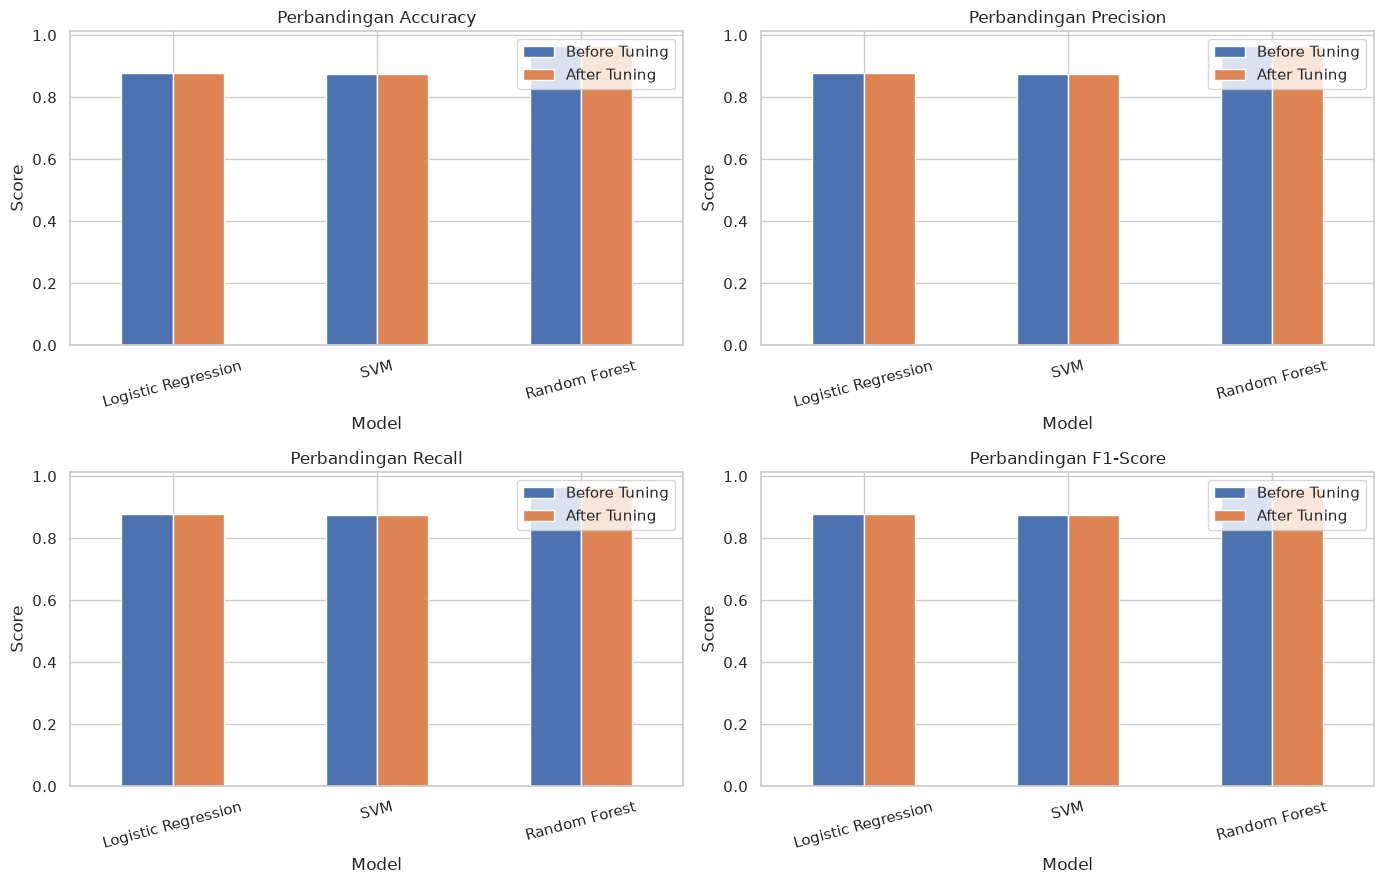

In [43]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    comparison_tuning_df.plot(
        x="Model",
        y=[f"{metric}_Before", f"{metric}_After"],
        kind="bar",
        ax=axes[i],
        rot=15
    )

    axes[i].set_title(f"Perbandingan {metric}")
    axes[i].set_xlabel("Model")
    axes[i].set_ylabel("Score")
    axes[i].legend(
        ["Before Tuning", "After Tuning"],
        loc="best"
    )

plt.tight_layout()
plt.show()